## Title: Visual SLAM with Dynamic Object Handling

### Goal: Build a complete Visual SLAM / Visual Odometry system that:

#### Estimates camera trajectory (Visual Odometry)

#### Detects and filters dynamic/moving objects

#### Builds a cleaner map by ignoring moving objects

#### Compares performance with vs without dynamic object filtering

#### Visualizes trajectory + map + dynamic masks

## Phase 1: Data Acquisition, Exploration & Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import cv2
import PIL
import torch
import warnings

from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

ROOT = '/kaggle/input/datasets/hocop1/kitti-odometry'

POSES_DIR = os.path.join(ROOT,'poses')
SEQUENCES_DIR = os.path.join(ROOT,'sequences')

print("Root exists      :", os.path.exists(ROOT))
print("Poses exists     :", os.path.exists(POSES_DIR))
print("Sequences exists :", os.path.exists(SEQUENCES_DIR))

#Available sequences
sequence_ids = sorted([d for d in os.listdir(SEQUENCES_DIR) if os.path.isdir(os.path.join(SEQUENCES_DIR,d))])
print(f'Available sequences: {sequence_ids}')


Root exists      : True
Poses exists     : True
Sequences exists : True
Available sequences: ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']


### Explore one sequence in detail

In [2]:
SEQ = '00'
seq_path = os.path.join(SEQUENCES_DIR,SEQ)

image_2_dir = os.path.join(seq_path, 'image_2')
image_3_dir = os.path.join(seq_path,'image_3')
calib_path = os.path.join(seq_path, 'calib.txt')
times_path = os.path.join(seq_path,'time.txt')
pose_path = os.path.join(POSES_DIR,f'{SEQ}.txt')

left_images = sorted(glob.glob(os.path.join(image_2_dir,'*.png')))
right_images = sorted(glob.glob(os.path.join(image_3_dir,'*.png')))

print(f"\nSequence {SEQ}:")
print(f"  Left images  : {len(left_images)}")
print(f"  Right images : {len(right_images)}")
print(f"  Pose file exists : {os.path.exists(pose_path)}")
print(f"  Calib file exists: {os.path.exists(calib_path)}")

# LOAD GROUND TRUTH POSES
def load_poses(pose_file):
    '''
    KITTI pose file: each line is a 3x4 matrix (flattened)
    Return a list of 4x4 tranformation matrices
    
    '''
    poses = []
    with open(pose_file,'r') as f:
        for line in f:
            values = list(map(float, line.strip().split()))
            pose = np.eye(4)
            pose[:3,:] = np.array(values).reshape(3,4)
            poses.append(pose)
    return poses


gt_poses = load_poses(pose_path)
print(f'Ground truth poses loaded: {len(gt_poses)}')

# Extract trajectory (x, z) for top-down view (KITTI is in camera coordinates)

gt_xyz = np.array([p[:3,3] for p in gt_poses])
print(f'Trajectory shape: {gt_xyz.shape}')

# NOW LOAD THE CALIBRATION
def load_calib(calib_file):
    data = {}
    with open(calib_file,'r') as f:
        for line in f:
            if ':' in line:
                key, value = line.split(':',1)
                data[key.strip()] = np.array([float(x) for x in value.split()])

    return data

calib = load_calib(calib_path)
print('Calibration keys: ', list(calib.keys()))

# P0 / P2 are projection matrices for left camera
P2 = calib['P2'].reshape(3,4)
print('Left camera Projection Matrix P2:\n', P2)


Sequence 00:
  Left images  : 4541
  Right images : 4541
  Pose file exists : True
  Calib file exists: True
Ground truth poses loaded: 4541
Trajectory shape: (4541, 3)
Calibration keys:  ['P0', 'P1', 'P2', 'P3', 'Tr']
Left camera Projection Matrix P2:
 [[ 7.188560e+02  0.000000e+00  6.071928e+02  4.538225e+01]
 [ 0.000000e+00  7.188560e+02  1.852157e+02 -1.130887e-01]
 [ 0.000000e+00  0.000000e+00  1.000000e+00  3.779761e-03]]


### VISUALIZE SAMPLE IMAGES

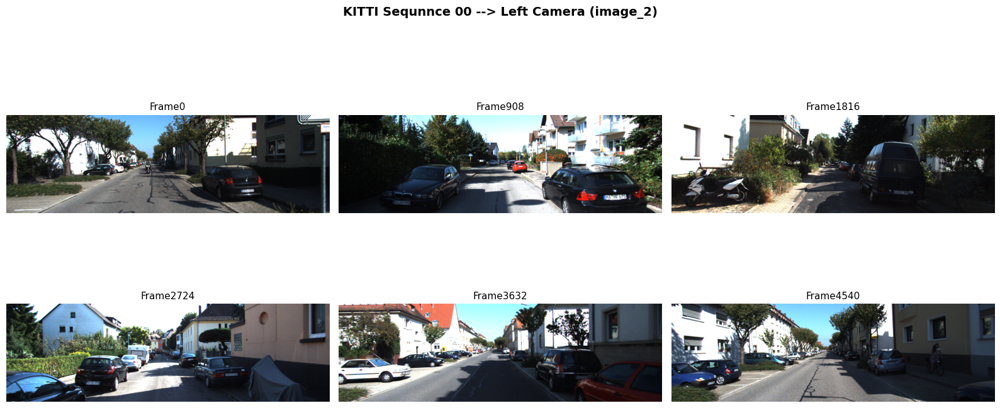

In [3]:
sample_indices = np.linspace(0, len(left_images) - 1,6,dtype=int)

fig, axes = plt.subplots(2,3,figsize=(16,8))
axes = axes.ravel()

for i, idx in enumerate(sample_indices):
    img = cv2.imread(left_images[idx])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(f'Frame{idx}',fontsize=11)
    axes[i].axis('off')

plt.suptitle(f'KITTI Sequnnce {SEQ} --> Left Camera (image_2)',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.show()

### VISUALIZE GROUND TRUTH TRAJECTORY

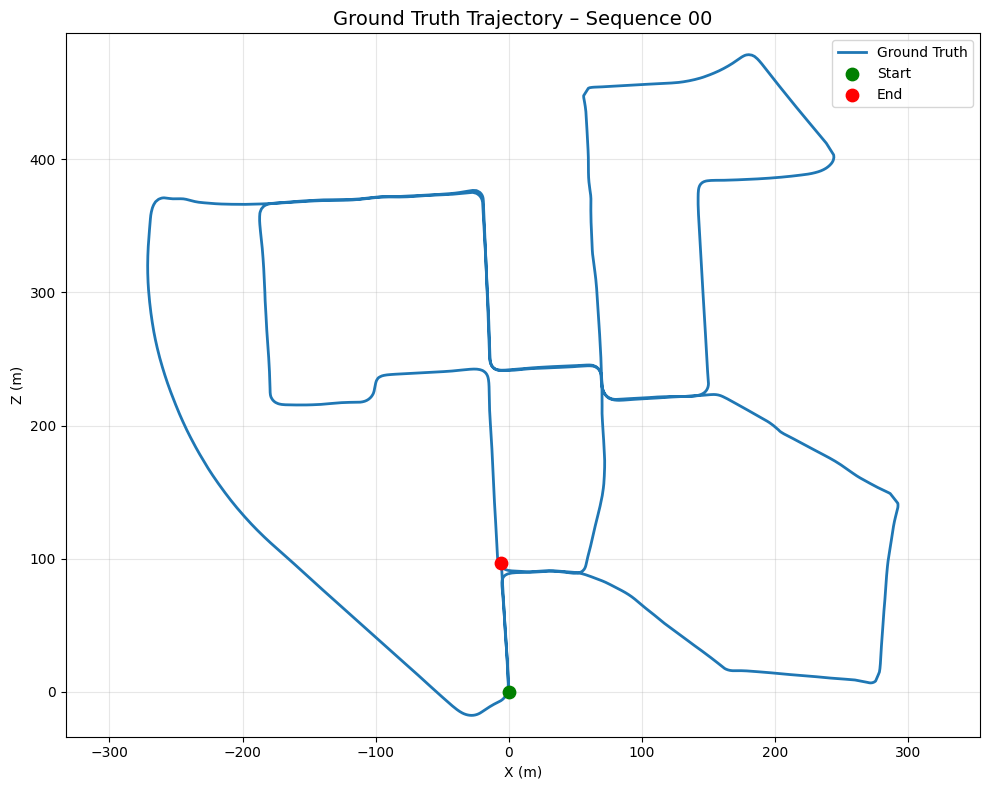

In [4]:
plt.figure(figsize=(10,8))
plt.plot(gt_xyz[:,0], gt_xyz[:,2], linewidth=2, label='Ground Truth')
plt.scatter(gt_xyz[0, 0], gt_xyz[0, 2], c="green", s=80, label="Start", zorder=5)
plt.scatter(gt_xyz[-1, 0], gt_xyz[-1, 2], c="red", s=80, label="End", zorder=5)
plt.xlabel("X (m)")
plt.ylabel("Z (m)")
plt.title(f"Ground Truth Trajectory – Sequence {SEQ}", fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.tight_layout()
plt.show()

### Sequence stats across all sequences

In [5]:
stats = []
for seq in sequence_ids:
    img_dir = os.path.join(SEQUENCES_DIR, seq, 'image_2')
    n_imgs = len(glob.glob(os.path.join(img_dir,'*.png')))
    pose_file = os.path.join(POSES_DIR, f'{seq}.txt')
    n_poses = sum(1 for _ in open(pose_file)) if os.path.exists(pose_file) else 0
    stats.append({
        "Sequence": seq,
        "Images": n_imgs,
        "Poses": n_poses
    })

stats_df = pd.DataFrame(stats)
display(stats_df)


,Sequence,Images,Poses
0,00,4541,4541
1,01,1101,1101
2,02,4661,4661
3,03,801,801
4,04,271,271
5,05,2761,2761
6,06,1101,1101
7,07,1101,1101
8,08,4071,4071
9,09,1591,1591


### FINAL SUMMARY

In [6]:
summary = pd.DataFrame({
    "Item": [
        "Dataset",
        "Sequences available",
        "Example sequence",
        "Images in Seq 00",
        "Ground Truth Poses",
        "Camera setup"
    ],
    "Value": [
        "KITTI Odometry",
        len(sequence_ids),
        SEQ,
        len(left_images),
        len(gt_poses),
        "Stereo (image_2 + image_3)"
    ]
})
display(summary)

,Item,Value
0,Dataset,KITTI Odometry
1,Sequences available,22
2,Example sequence,00
3,Images in Seq 00,4541
4,Ground Truth Poses,4541
5,Camera setup,Stereo (image_2 + image_3)


--------------------------------------------------------

## Phase 2: Feature Detection & Matching (ORB)

ORB detector initialized.


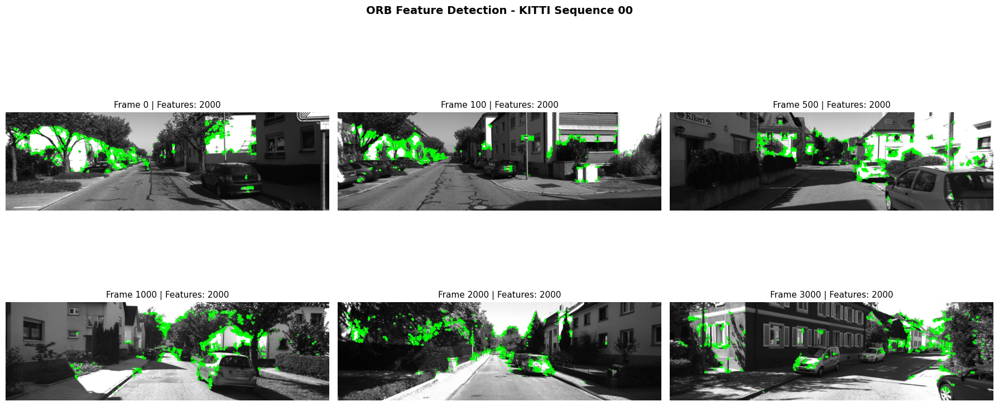

In [7]:
import random
from tqdm.auto import tqdm

#INitialize ORB Detector
orb = cv2.ORB_create(
    nfeatures=2000,          # max number of features
    scaleFactor=1.2,
    nlevels=8,
    edgeThreshold=31,
    firstLevel=0,
    WTA_K=2,
    scoreType=cv2.ORB_HARRIS_SCORE,
    patchSize=31
)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

print("ORB detector initialized.")

#Feature detection on a single frame

def detect_orb(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    keypoints, descriptors = orb.detectAndCompute(img, None)
    return img, keypoints, descriptors

#Test on a few frames
sample_indices = [0,100,500,1000,2000,3000]

fig, axes = plt.subplots(2,3,figsize=(18,9))
axes = axes.ravel()

for i, idx in enumerate(sample_indices):
    img, kps, des = detect_orb(left_images[idx])
    img_color = cv2.drawKeypoints(img, kps, None, color=(0,255,0), flags=0)

    axes[i].imshow(img_color, cmap='gray')
    axes[i].set_title(f'Frame {idx} | Features: {len(kps)}',fontsize=11)
    axes[i].axis('off')

plt.suptitle('ORB Feature Detection - KITTI Sequence 00',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.show()



### Feature Matching between consecutive frames


>>> Feature Matching between consecutive frames


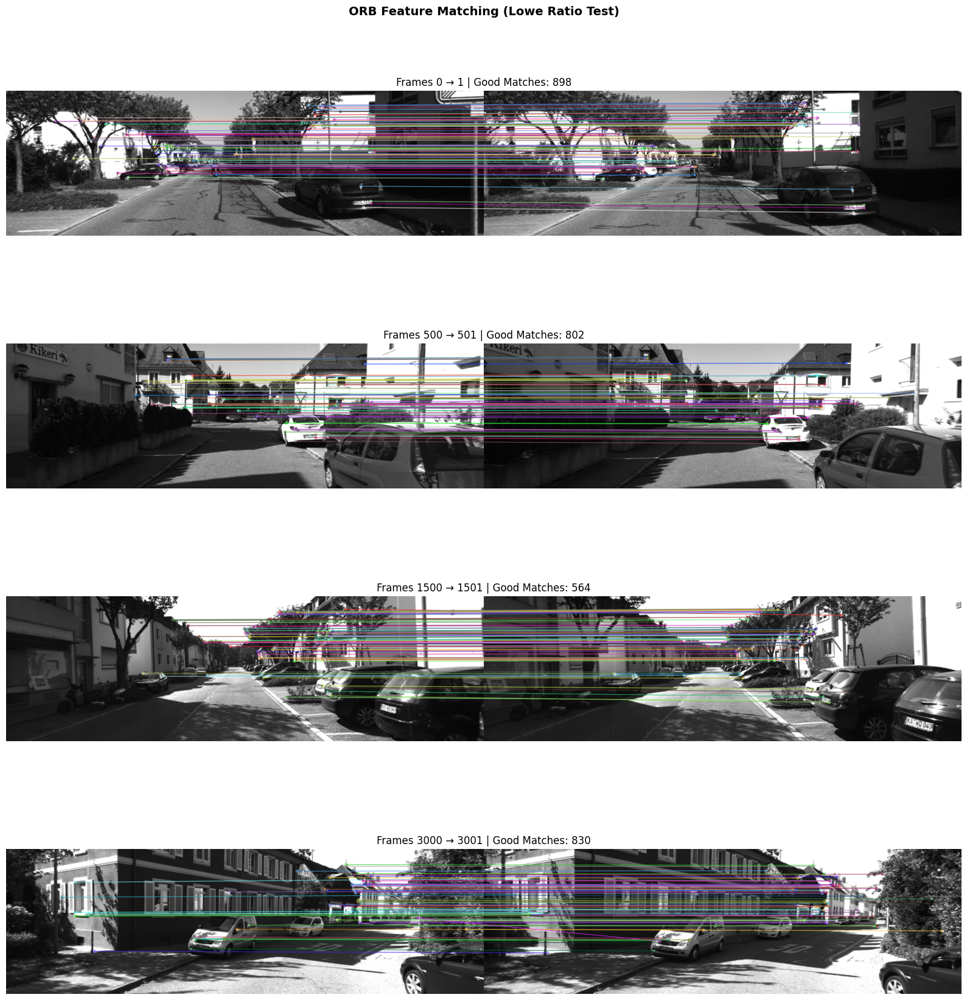

In [8]:
def match_frames(img_path1, img_path2, ratio_thresh=0.75):
    img1, kps1, des1 = detect_orb(img_path1)
    img2, kps2, des2 = detect_orb(img_path2)
    
    if des1 is None or des2 is None:
        return img1, img2, kps1, kps2, []
    
    # KNN Matching
    matches = bf.knnMatch(des1, des2, k=2)
    
    # Lowe's ratio test
    good_matches = []
    for m, n in matches:
        if m.distance < ratio_thresh * n.distance:
            good_matches.append(m)
    
    return img1, img2, kps1, kps2, good_matches


# Visualize matching
print("\n>>> Feature Matching between consecutive frames")

pair_indices = [(0, 1), (500, 501), (1500, 1501), (3000, 3001)]

fig, axes = plt.subplots(4, 1, figsize=(16, 18))

for i, (idx1, idx2) in enumerate(pair_indices):
    img1, img2, kps1, kps2, good = match_frames(left_images[idx1], left_images[idx2])
    
    matched_img = cv2.drawMatches(
        img1, kps1, img2, kps2, good[:80], None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    
    axes[i].imshow(matched_img)
    axes[i].set_title(f"Frames {idx1} → {idx2} | Good Matches: {len(good)}", fontsize=12)
    axes[i].axis("off")

plt.suptitle("ORB Feature Matching (Lowe Ratio Test)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

    

### Matching Quality Stats

  0%|          | 0/100 [00:00<?, ?it/s]


Average good matches per pair : 971.2
Min matches                   : 468
Max matches                   : 1358


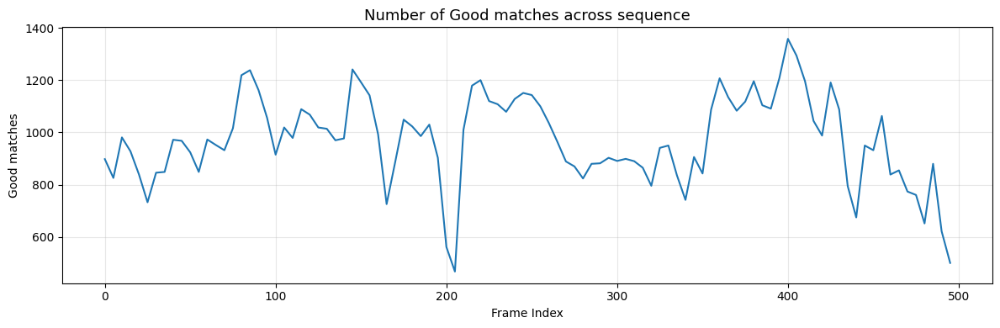

In [9]:
num_matches_list = []
sample_range = range(0, min(500, len(left_images)-1),5)

for i in tqdm(sample_range):
    _,_,_,_, good = match_frames(left_images[i], left_images[i+1])
    num_matches_list.append(len(good))

print(f"\nAverage good matches per pair : {np.mean(num_matches_list):.1f}")
print(f"Min matches                   : {min(num_matches_list)}")
print(f"Max matches                   : {max(num_matches_list)}")

plt.figure(figsize=(12,4))
plt.plot(list(sample_range), num_matches_list, linewidth=1.5)
plt.title('Number of Good matches across sequence',fontsize=13)
plt.xlabel('Frame Index')
plt.ylabel('Good matches')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### SUMMARY

In [10]:
summary = pd.DataFrame({
    "Item": [
        "Feature Detector",
        "Max Features",
        "Matching Method",
        "Average Good Matches",
        "Sequence Used"
    ],
    "Value": [
        "ORB",
        2000,
        "BFMatcher + Lowe Ratio Test",
        f"{np.mean(num_matches_list):.1f}",
        SEQ
    ]
})
display(summary)

,Item,Value
0,Feature Detector,ORB
1,Max Features,2000
2,Matching Method,BFMatcher + Lowe Ratio Test
3,Average Good Matches,971.2
4,Sequence Used,00


-------------------------------------------------------

## Phase 3: Classic Visual Odometry Pipeline

#### In this phase we build a complete monocular Visual Odometry system:

##### Feature matching between consecutive frames

##### Essential Matrix estimation

##### Pose recovery (R, t)

##### Scale recovery using ground truth

##### Full trajectory estimation

In [11]:
### PATHS AND CALIBRATION
seq_path = os.path.join(ROOT, 'sequences',SEQ)
image_2_dir = os.path.join(seq_path, 'image_2')
pose_path = os.path.join(ROOT,'poses',f'{SEQ}.txt')
calib_path = os.path.join(seq_path, 'calib.txt')

left_images = sorted(glob.glob(os.path.join(image_2_dir,'*.png')))
print(f'Total frames: {len(left_images)}')

#Load calibration
def load_calib(calib_file):
    data = {}
    with open(calib_file,'r') as f:
        for line in f:
            if ':' in line:
                key, value = line.split(':',1)
                data[key.strip()] = np.array([float(x) for x in value.split()])

    return data

calib = load_calib(calib_path)
P2 = calib['P2'].reshape(3,4)

#FOCAL LENGTH and PRINCIPLE POINT FROM P2
fx = P2[0, 0]
fy = P2[1, 1]
cx = P2[0, 2]
cy = P2[1, 2]
K = np.array([[fx, 0, cx],
              [0, fy, cy],
              [0,  0,  1]])

print("Camera Intrinsic Matrix K:\n", K)

#LOAD GROUND TRUTH

def load_poses(pose_file):
    poses = []
    with open(pose_file,'r') as f:
        for line in f:
            values = list(map(float, line.strip().split()))
            pose = np.eye(4)
            pose[:3,:] = np.array(values).reshape(3,4)
            poses.append(pose)

    return poses

gt_poses = load_poses(pose_path)
gt_xyz = np.array([p[:3,3] for p in gt_poses])
print(f'Ground truth poses: {len(gt_poses)}')


                

Total frames: 4541
Camera Intrinsic Matrix K:
 [[718.856    0.     607.1928]
 [  0.     718.856  185.2157]
 [  0.       0.       1.    ]]
Ground truth poses: 4541


### ORB + MATCHING HELPER FUNCTIONS

  0%|          | 0/800 [00:00<?, ?it/s]

Estimated trajectory shape: (801, 3)


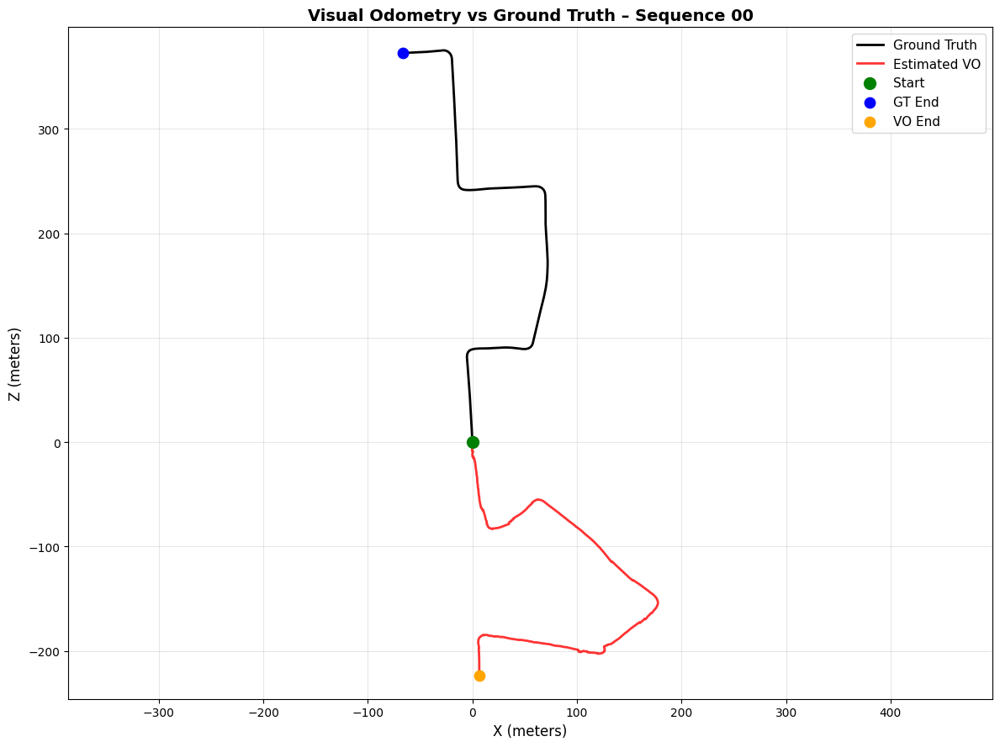

In [12]:
orb = cv2.ORB_create(nfeatures=2500)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

def detect_and_match(img1_path, img2_path, ratio=0.75):
    img1 = cv2.imread(img1_path, cv2.IMREAD_GRAYSCALE)
    img2 = cv2.imread(img2_path, cv2.IMREAD_GRAYSCALE)

    kps1, des1 = orb.detectAndCompute(img1, None)
    kps2, des2 = orb.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        return None, None ,[]

    matches = bf.knnMatch(des1, des2, k=2)
    good = []
    for m, n in matches:
        if m.distance < ratio * n.distance:
            good.append(m)

    pts1 = np.float32([kps1[m.queryIdx].pt for m in good])
    pts2 = np.float32([kps2[m.trainIdx].pt for m in good])


    return pts1, pts2, good


#POSE ESTIMATION FUNCTION

def estimate_pose(pts1,pts2,K):
    '''
    This estimates relative pose (R,t) from matched points
    '''

    #ESSENTIAL MATRIX
    E, mask = cv2.findEssentialMat(
        pts1, pts2, K,
        method=cv2.RANSAC,
        prob = 0.999,
        threshold=1.0
    )

    if E is None:
        return None, None , 0

    #REVOVER POSE
    _, R, t, mask_pose = cv2.recoverPose(E, pts1, pts2, K, mask=mask)

    inliers = int(mask_pose.sum()) if mask_pose is not None else 0
    return R,t , inliers


#FULL VISUAL ODOMETRY ON SEQUENCE

#we will process a subset first for speed( you can increase this later if you want )

MAX_FRAMES = 800
step = 1

estimated_poses = [np.eye(4)]
current_pose = np.eye(4)

trajectory = [np.array([0.0,0.0,0.0])]

for i in tqdm(range(0, min(MAX_FRAMES, len(left_images)-1),step)):
    pts1, pts2, good = detect_and_match(left_images[i], left_images[i+step])


    if pts1 is None or len(good) < 30:
        #not enough matches --> assume small motion
        estimated_poses.append(current_pose.copy())
        trajectory.append(current_pose[:3,3].copy())
        continue

    R, t, inliers = estimate_pose(pts1, pts2,K)

    if R is None:
        estimated_poses.append(current_pose.copy())
        trajectory.append(current_pose[:3,3].copy())
        continue

    #Scale recovery using ground truth
    gt_motion = gt_poses[i+step][:3,3] - gt_poses[i][:3,3]
    scale = np.linalg.norm(gt_motion)

    #Avoid zero scale
    if scale < 1e-6:
        scale = 1.0

    t = t*scale

    #update pose
    relative_pose = np.eye(4)
    relative_pose[:3,:3] = R
    relative_pose[:3,3] = t.flatten()

    current_pose = current_pose @ relative_pose
    estimated_poses.append(current_pose.copy())
    trajectory.append(current_pose[:3,3].copy())

trajectory = np.array(trajectory)
print(f'Estimated trajectory shape: {trajectory.shape}')


#NOW VISUALIZE ESTIMATED vs GROUND TRUTH TRAJECTORY
gt_xyz_subset = gt_xyz[:len(trajectory)]\

plt.figure(figsize=(12,9))
plt.plot(gt_xyz_subset[:, 0], gt_xyz_subset[:, 2], 
         label="Ground Truth", linewidth=2, color="black")
plt.plot(trajectory[:, 0], trajectory[:, 2], 
         label="Estimated VO", linewidth=2, color="red", alpha=0.8)

plt.scatter(gt_xyz_subset[0, 0], gt_xyz_subset[0, 2], c="green", s=100, label="Start", zorder=5)
plt.scatter(gt_xyz_subset[-1, 0], gt_xyz_subset[-1, 2], c="blue", s=80, label="GT End", zorder=5)
plt.scatter(trajectory[-1, 0], trajectory[-1, 2], c="orange", s=80, label="VO End", zorder=5)

plt.xlabel("X (meters)", fontsize=12)
plt.ylabel("Z (meters)", fontsize=12)
plt.title(f"Visual Odometry vs Ground Truth – Sequence {SEQ}", fontsize=14, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()

### SIMPLE ERROR METRICS

In [13]:
min_len = min(len(trajectory), len(gt_xyz_subset))
traj = trajectory[:min_len]
gt = gt_xyz_subset[:min_len]

#Absolute trajectory error (ATE) - RMSE
ate = np.sqrt(np.mean(np.sum((traj - gt)**2,axis=1)))
print(f"\nAbsolute Trajectory Error (RMSE): {ate:.3f} meters")

#Final drift
final_drift = np.linalg.norm(traj[-1] - gt[-1])
print(f"Final position drift           : {final_drift:.3f} meters")




Absolute Trajectory Error (RMSE): 379.576 meters
Final position drift           : 602.014 meters


### SUMMARY

In [14]:
summary = pd.DataFrame({
    "Item": [
        "Sequence",
        "Frames processed",
        "Feature Detector",
        "Pose Estimation",
        "Scale Recovery",
        "ATE (RMSE)",
        "Final Drift"
    ],
    "Value": [
        SEQ,
        len(trajectory),
        "ORB",
        "Essential Matrix + recoverPose",
        "Ground Truth",
        f"{ate:.3f} m",
        f"{final_drift:.3f} m"
    ]
})
display(summary)

,Item,Value
0,Sequence,00
1,Frames processed,801
2,Feature Detector,ORB
3,Pose Estimation,Essential Matrix + recoverPose
4,Scale Recovery,Ground Truth
5,ATE (RMSE),379.576 m
6,Final Drift,602.014 m


------------------------------------------------

## Phase 4: Dynamic Object Detection

##### In this phase we detect potential dynamic objects (cars, pedestrians, cyclists, trucks, buses, etc.) so we can later remove features that fall on them.

In [15]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.2 MB/s eta 0:00:00
  Attempting uninstall: nvidia-ml-py
    Found existing installation: nvidia-ml-py 11.495.46
    Uninstalling nvidia-ml-py-11.495.46:
      Successfully uninstalled nvidia-ml-py-11.495.46
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gpustat 1.0.0 requires nvidia-ml-py<=11.495.46,>=11.450.129, but you have nvidia-ml-py 13.615.71 which is incompatible.


In [16]:
from ultralytics import YOLO

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

#NOW LOAD THE YOLO model
yolo_model = YOLO('yolov8m.pt')
print('YOLO LOADED')

#COCO classes that are typically dynamic in driving scenes
DYNAMIC_CLASSES = {
    0: "person",
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck",
    9: "traffic light"          # optional
}

print('Dynamic classes we will detect: ',list(DYNAMIC_CLASSES.values()))

#PATH of left images is
left_images = sorted(glob.glob(os.path.join(image_2_dir,'*.png')))
print(f'Total frames available: {len(left_images)}')



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Using device: cuda
YOLO LOADED
Dynamic classes we will detect:  ['person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic light']
Total frames available: 4541


### Detect dynamic objects on sample frames

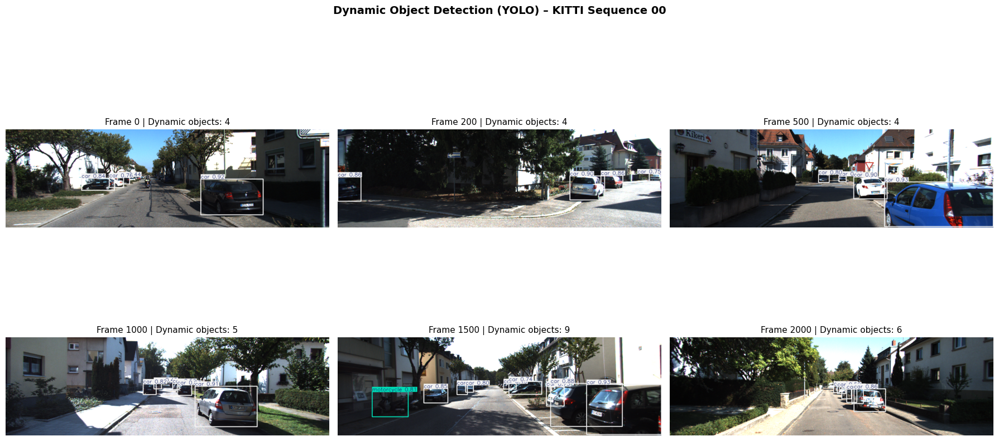

In [17]:
sample_indices = [0, 200, 500, 1000, 1500, 2000]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, idx in enumerate(sample_indices):
    results = yolo_model.predict(
        left_images[idx],
        conf=0.4,
        classes=list(DYNAMIC_CLASSES.keys()),
        verbose=False
    )
    
    annotated = results[0].plot()
    annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    
    num_dets = len(results[0].boxes) if results[0].boxes is not None else 0
    
    axes[i].imshow(annotated)
    axes[i].set_title(f"Frame {idx} | Dynamic objects: {num_dets}", fontsize=11)
    axes[i].axis("off")

plt.suptitle("Dynamic Object Detection (YOLO) – KITTI Sequence 00", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Create Dynamic Masks


>>> Dynamic Masks


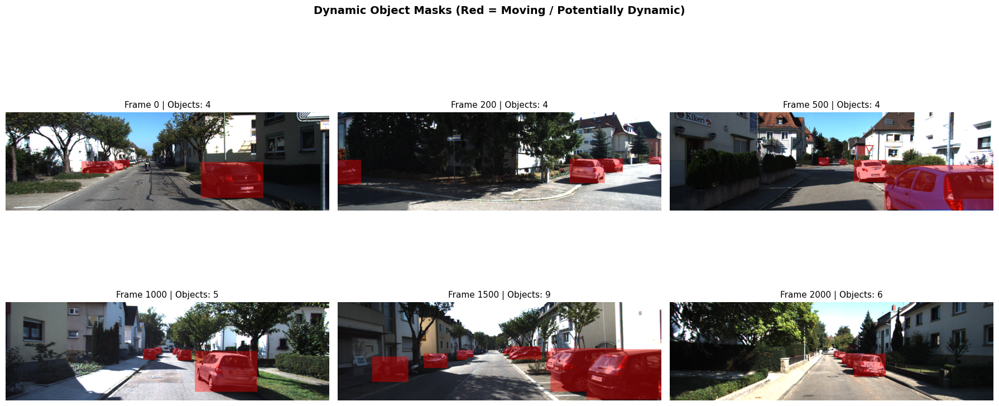

In [18]:
def create_dynamic_mask(img_path, conf=0.4):
    """
    Returns:
        mask (H, W) – 255 where dynamic objects are, 0 elsewhere
        num_objects
    """
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    
    results = yolo_model.predict(
        img_path,
        conf=conf,
        classes=list(DYNAMIC_CLASSES.keys()),
        verbose=False
    )
    
    result = results[0]
    num_objects = 0
    
    if result.boxes is not None and len(result.boxes) > 0:
        boxes = result.boxes.xyxy.cpu().numpy()
        num_objects = len(boxes)
        for box in boxes:
            x1, y1, x2, y2 = map(int, box)
            cv2.rectangle(mask, (x1, y1), (x2, y2), 255, -1)   # filled
    
    return mask, num_objects


# Visualize masks
print("\n>>> Dynamic Masks")

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()

for i, idx in enumerate(sample_indices):
    mask, num_obj = create_dynamic_mask(left_images[idx])
    img = cv2.imread(left_images[idx])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Overlay mask
    overlay = img.copy()
    overlay[mask == 255] = [255, 0, 0]          # red for dynamic regions
    blended = cv2.addWeighted(img, 0.6, overlay, 0.4, 0)
    
    axes[i].imshow(blended)
    axes[i].set_title(f"Frame {idx} | Objects: {num_obj}", fontsize=11)
    axes[i].axis("off")

plt.suptitle("Dynamic Object Masks (Red = Moving / Potentially Dynamic)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### STATS of Dynamic Objects

& 

### SUMMARY

In [19]:
sample_for_stats = random.sample(range(len(left_images)),100)
obj_counts = []

for idx in tqdm(sample_for_stats):
    _, num = create_dynamic_mask(left_images[idx])
    obj_counts.append(num)

print(f"\nAverage dynamic objects per frame : {np.mean(obj_counts):.2f}")
print(f"Frames with at least 1 dynamic object: {sum(1 for x in obj_counts if x > 0)}")
print(f"Max dynamic objects in one frame   : {max(obj_counts)}")


#SUMMARY

print('Here is the Summary')

summary = pd.DataFrame({
    "Item": [
        "Detector",
        "Dynamic Classes",
        "Avg objects / frame",
        "Frames with dynamic objects",
        "Mask type"
    ],
    "Value": [
        "YOLOv8m",
        "person, car, bus, truck, bicycle, motorcycle",
        f"{np.mean(obj_counts):.2f}",
        f"{sum(1 for x in obj_counts if x > 0)} / 100",
        "Binary (255 = dynamic)"
    ]
})
display(summary)

  0%|          | 0/100 [00:00<?, ?it/s]


Average dynamic objects per frame : 5.18
Frames with at least 1 dynamic object: 98
Max dynamic objects in one frame   : 14
Here is the Summary


,Item,Value
0,Detector,YOLOv8m
1,Dynamic Classes,"person, car, bus, truck, bicycle, motorcycle"
2,Avg objects / frame,5.18
3,Frames with dynamic objects,98 / 100
4,Mask type,Binary (255 = dynamic)


------------------------------------------------

## Phase 5: Dynamic Object Filtering for Visual Odometry

### In this phase we:

#### Detect dynamic objects

#### Remove ORB features that fall inside dynamic regions

#### Re-run Visual Odometry using only static features

#### Compare the new trajectory against the original (unfiltered) VO

  0%|          | 0/600 [00:00<?, ?it/s]

Filtered trajectory shape: (601, 3)


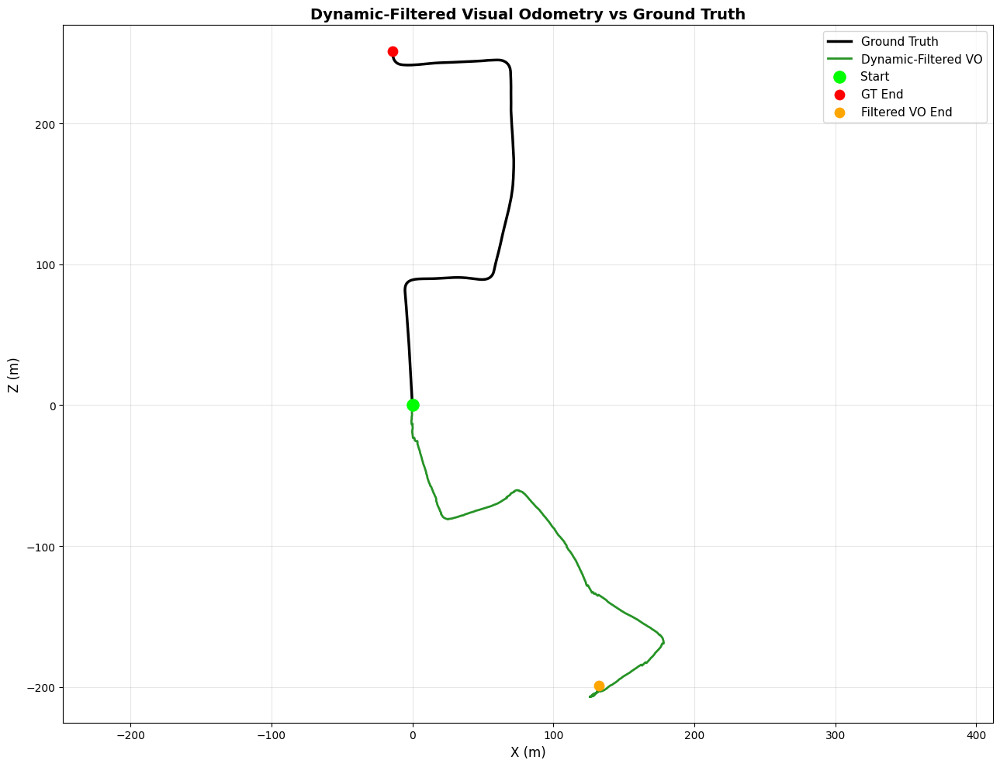

In [20]:
import random
import os
import cv2

left_images = sorted(glob.glob(os.path.join(image_2_dir, "*.png")))

# Calibration
def load_calib(calib_file):
    data = {}
    with open(calib_file, "r") as f:
        for line in f:
            if ":" in line:
                key, value = line.split(":", 1)
                data[key.strip()] = np.array([float(x) for x in value.split()])
    return data

calib = load_calib(calib_path)
P2 = calib["P2"].reshape(3, 4)
fx, fy, cx, cy = P2[0,0], P2[1,1], P2[0,2], P2[1,2]
K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]])

# Ground Truth
def load_poses(pose_file):
    poses = []
    with open(pose_file, "r") as f:
        for line in f:
            values = list(map(float, line.strip().split()))
            pose = np.eye(4)
            pose[:3, :] = np.array(values).reshape(3, 4)
            poses.append(pose)
    return poses

gt_poses = load_poses(pose_path)
gt_xyz = np.array([p[:3, 3] for p in gt_poses])

# ----------------------------------------------------------
# 2. Dynamic classes
# ----------------------------------------------------------
DYNAMIC_CLASSES = [0, 1, 2, 3, 5, 7]   # person, bicycle, car, motorcycle, bus, truck

# ----------------------------------------------------------
# 3. Helper: Create dynamic mask
# ----------------------------------------------------------
def get_dynamic_mask(img_path, conf=0.4):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    results = yolo_model.predict(
        img_path,
        conf=conf,
        classes=DYNAMIC_CLASSES,
        verbose=False
    )
    if results[0].boxes is not None:
        for box in results[0].boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = map(int, box)
            cv2.rectangle(mask, (x1, y1), (x2, y2), 255, -1)
    return mask


# ----------------------------------------------------------
# 4. ORB with Dynamic Filtering
# ----------------------------------------------------------
orb = cv2.ORB_create(nfeatures=2500)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

def detect_and_match_static(img_path1, img_path2, ratio=0.75):
    img1 = cv2.imread(img_path1, cv2.IMREAD_GRAYSCALE)
    img2 = cv2.imread(img_path2, cv2.IMREAD_GRAYSCALE)

    # Detect
    kps1, des1 = orb.detectAndCompute(img1, None)
    kps2, des2 = orb.detectAndCompute(img2, None)

    if des1 is None or des2 is None or len(kps1) < 20 or len(kps2) < 20:
        return None, None, 0, 0

    # Dynamic masks
    mask1 = get_dynamic_mask(img_path1)
    mask2 = get_dynamic_mask(img_path2)

    # Keep only keypoints that fall on STATIC regions
    static_idx1 = [i for i, kp in enumerate(kps1) if mask1[int(kp.pt[1]), int(kp.pt[0])] == 0]
    static_idx2 = [i for i, kp in enumerate(kps2) if mask2[int(kp.pt[1]), int(kp.pt[0])] == 0]

    if len(static_idx1) < 20 or len(static_idx2) < 20:
        return None, None, len(static_idx1), len(static_idx2)

    kps1_static = [kps1[i] for i in static_idx1]
    des1_static = des1[static_idx1]
    kps2_static = [kps2[i] for i in static_idx2]
    des2_static = des2[static_idx2]

    # Matching
    matches = bf.knnMatch(des1_static, des2_static, k=2)
    good = []
    for m, n in matches:
        if m.distance < ratio * n.distance:
            good.append(m)

    if len(good) < 20:
        return None, None, len(static_idx1), len(static_idx2)

    pts1 = np.float32([kps1_static[m.queryIdx].pt for m in good])
    pts2 = np.float32([kps2_static[m.trainIdx].pt for m in good])

    return pts1, pts2, len(static_idx1), len(good)


#RUN FILTERED VISUAL ODOMETRY

MAX_FRAMES = 600
estimated_poses_filt = [np.eye(4)]
current_pose = np.eye(4)
trajectory_filt = [np.array([0.0, 0.0, 0.0])]
static_features_log = []
good_matches_log = []

for i in tqdm(range(0, min(MAX_FRAMES, len(left_images)-1))):
    pts1, pts2, n_static, n_good = detect_and_match_static(left_images[i], left_images[i+1])
    
    static_features_log.append(n_static)
    good_matches_log.append(n_good if pts1 is not None else 0)

    if pts1 is None:
        estimated_poses_filt.append(current_pose.copy())
        trajectory_filt.append(current_pose[:3, 3].copy())
        continue

    # Essential Matrix + Recover Pose
    E, mask = cv2.findEssentialMat(pts1, pts2, K, method=cv2.RANSAC, prob=0.999, threshold=1.0)
    if E is None:
        estimated_poses_filt.append(current_pose.copy())
        trajectory_filt.append(current_pose[:3, 3].copy())
        continue

    _, R, t, _ = cv2.recoverPose(E, pts1, pts2, K, mask=mask)

    # Scale from ground truth
    gt_motion = gt_poses[i+1][:3, 3] - gt_poses[i][:3, 3]
    scale = np.linalg.norm(gt_motion)
    if scale < 1e-6:
        scale = 1.0
    t = t * scale

    relative_pose = np.eye(4)
    relative_pose[:3, :3] = R
    relative_pose[:3, 3] = t.flatten()

    current_pose = current_pose @ relative_pose
    estimated_poses_filt.append(current_pose.copy())
    trajectory_filt.append(current_pose[:3, 3].copy())

trajectory_filt = np.array(trajectory_filt)
print(f"Filtered trajectory shape: {trajectory_filt.shape}")
# COMPARE TRAJECTORIES

gt_subset = gt_xyz[:len(trajectory_filt)]

plt.figure(figsize=(13,10))
plt.plot(gt_subset[:, 0], gt_subset[:, 2], label="Ground Truth", linewidth=2.5, color="black")
plt.plot(trajectory_filt[:, 0], trajectory_filt[:, 2], label="Dynamic-Filtered VO", linewidth=2, color="green", alpha=0.85)

plt.scatter(gt_subset[0, 0], gt_subset[0, 2], c="lime", s=120, label="Start", zorder=5)
plt.scatter(gt_subset[-1, 0], gt_subset[-1, 2], c="red", s=80, label="GT End", zorder=5)
plt.scatter(trajectory_filt[-1, 0], trajectory_filt[-1, 2], c="orange", s=80, label="Filtered VO End", zorder=5)

plt.xlabel("X (m)", fontsize=12)
plt.ylabel("Z (m)", fontsize=12)
plt.title("Dynamic-Filtered Visual Odometry vs Ground Truth", fontsize=14, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.tight_layout()
plt.show()
        

### METRICS & SUMMARY

In [21]:
min_len = min(len(trajectory_filt), len(gt_subset))
traj = trajectory_filt[:min_len]
gt = gt_subset[:min_len]

ate_filt = np.sqrt(np.mean(np.sum((traj - gt)**2, axis=1)))
final_drift_filt = np.linalg.norm(traj[-1] - gt[-1])

print(f"\nDynamic-Filtered VO Results:")
print(f"  ATE (RMSE)     : {ate_filt:.3f} meters")
print(f"  Final Drift    : {final_drift_filt:.3f} meters")
print(f"  Avg static features kept : {np.mean(static_features_log):.1f}")
print(f"  Avg good matches         : {np.mean(good_matches_log):.1f}")


#SUMMARY
print('\nHere is the SUMMARY')

summary = pd.DataFrame({
    "Item": [
        "Method",
        "Frames processed",
        "ATE (RMSE)",
        "Final Drift",
        "Avg Static Features",
        "Avg Good Matches"
    ],
    "Value": [
        "ORB + Dynamic Filtering",
        len(trajectory_filt),
        f"{ate_filt:.3f} m",
        f"{final_drift_filt:.3f} m",
        f"{np.mean(static_features_log):.1f}",
        f"{np.mean(good_matches_log):.1f}"
    ]
})
display(summary)


Dynamic-Filtered VO Results:
  ATE (RMSE)     : 319.001 meters
  Final Drift    : 473.820 meters
  Avg static features kept : 1980.7
  Avg good matches         : 1018.9

Here is the SUMMARY


,Item,Value
0,Method,ORB + Dynamic Filtering
1,Frames processed,601
2,ATE (RMSE),319.001 m
3,Final Drift,473.820 m
4,Avg Static Features,1980.7
5,Avg Good Matches,1018.9


------------------------------------------------

## Phase 6: Side-by-side Comparison + Feature Visualization

>>> Static vs Dynamic Feature Visualization


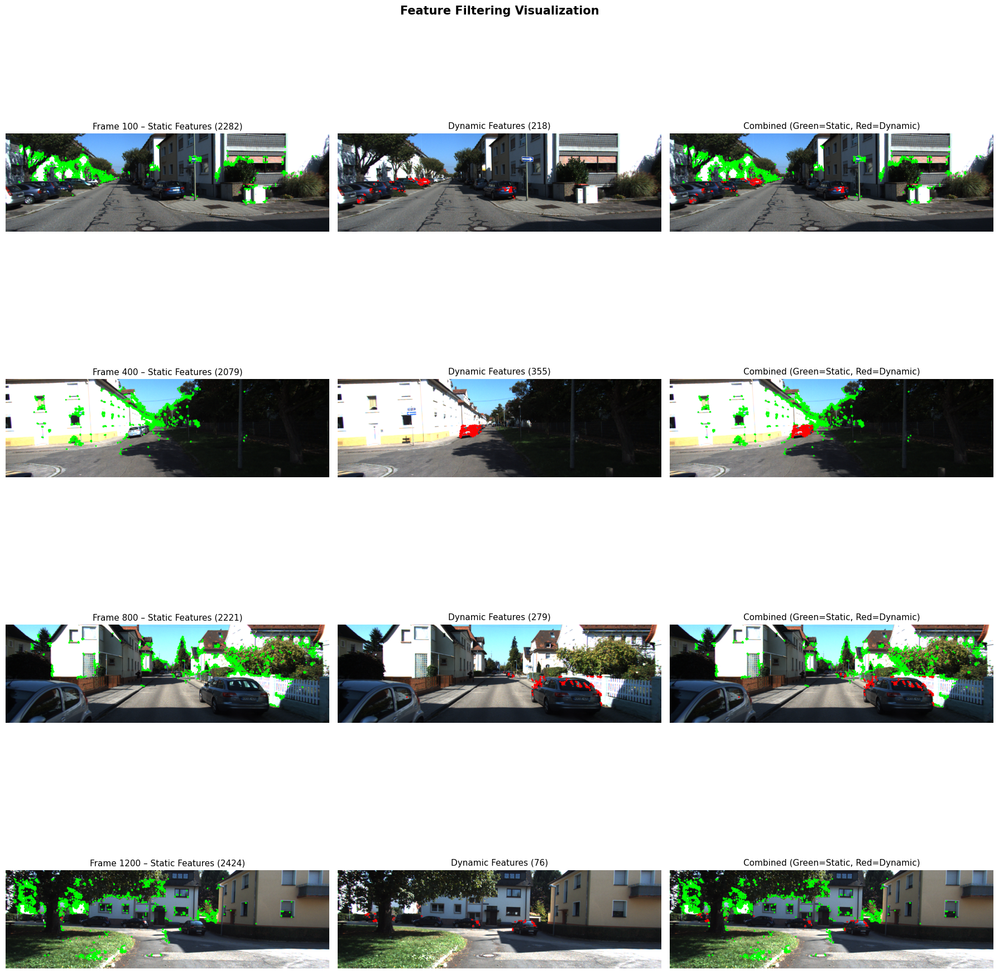

In [22]:
def get_dynamic_mask(img_path, conf=0.4):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    results = yolo_model.predict(img_path, conf=conf, classes=DYNAMIC_CLASSES, verbose=False)
    if results[0].boxes is not None:
        for box in results[0].boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = map(int, box)
            cv2.rectangle(mask, (x1, y1), (x2, y2), 255, -1)
    return mask

# ----------------------------------------------------------
# 2. Visualize Static vs Dynamic Features
# ----------------------------------------------------------
def visualize_static_vs_dynamic_features(img_path):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Detect ORB
    kps, des = orb.detectAndCompute(gray, None)
    
    # Dynamic mask
    mask = get_dynamic_mask(img_path)
    
    # Separate keypoints
    static_kps = []
    dynamic_kps = []
    
    for kp in kps:
        x, y = int(kp.pt[0]), int(kp.pt[1])
        if mask[y, x] == 255:
            dynamic_kps.append(kp)
        else:
            static_kps.append(kp)
    
    # Draw
    img_static = img_rgb.copy()
    img_dynamic = img_rgb.copy()
    img_both = img_rgb.copy()
    
    # Static = Green
    for kp in static_kps:
        x, y = map(int, kp.pt)
        cv2.circle(img_static, (x, y), 3, (0, 255, 0), -1)
        cv2.circle(img_both, (x, y), 3, (0, 255, 0), -1)
    
    # Dynamic = Red
    for kp in dynamic_kps:
        x, y = map(int, kp.pt)
        cv2.circle(img_dynamic, (x, y), 3, (255, 0, 0), -1)
        cv2.circle(img_both, (x, y), 3, (255, 0, 0), -1)
    
    return img_static, img_dynamic, img_both, len(static_kps), len(dynamic_kps)


print(">>> Static vs Dynamic Feature Visualization")

sample_indices = [100, 400, 800, 1200]

fig, axes = plt.subplots(len(sample_indices), 3, figsize=(18, 5*len(sample_indices)))

for i, idx in enumerate(sample_indices):
    img_static, img_dynamic, img_both, n_static, n_dynamic = visualize_static_vs_dynamic_features(left_images[idx])
    
    axes[i, 0].imshow(img_static)
    axes[i, 0].set_title(f"Frame {idx} – Static Features ({n_static})", fontsize=11)
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(img_dynamic)
    axes[i, 1].set_title(f"Dynamic Features ({n_dynamic})", fontsize=11)
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(img_both)
    axes[i, 2].set_title("Combined (Green=Static, Red=Dynamic)", fontsize=11)
    axes[i, 2].axis("off")

plt.suptitle("Feature Filtering Visualization", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


    

### Side by Side Trajectory Comparison


##### We reuse the trajectories from previous phases if available.
##### For safety we recompute a short version of both.

Original:   0%|          | 0/400 [00:00<?, ?it/s]

Filtered:   0%|          | 0/400 [00:00<?, ?it/s]

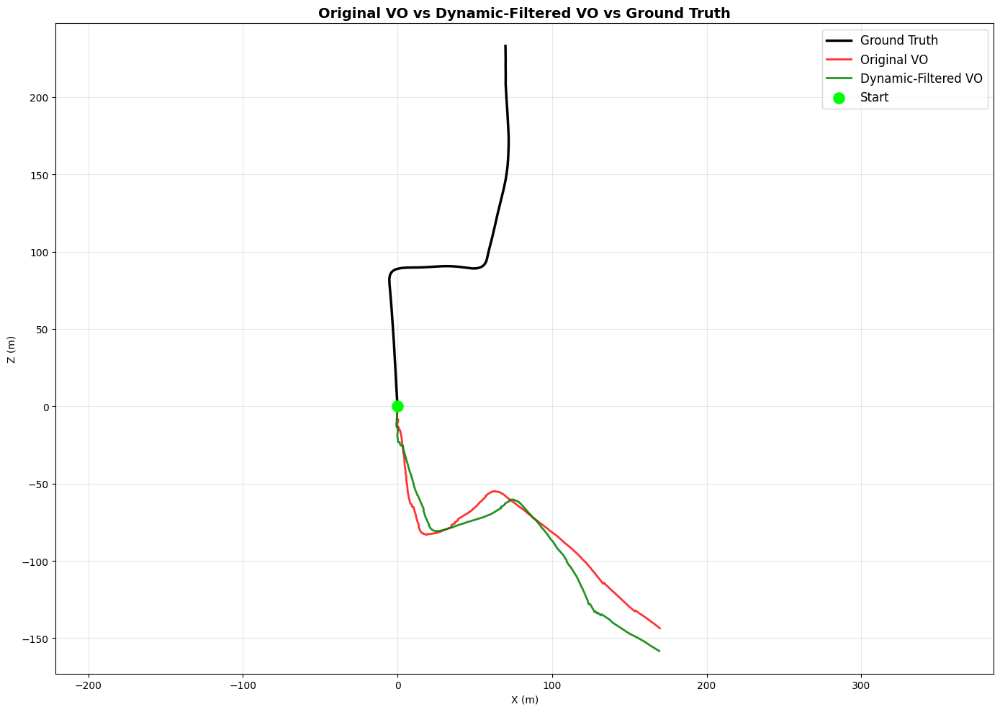

In [23]:
def run_vo(filter_dynamic=False, max_frames=400):
    current_pose = np.eye(4)
    trajectory = [np.array([0., 0., 0.])]
    
    for i in tqdm(range(max_frames), desc="Filtered" if filter_dynamic else "Original"):
        img1 = cv2.imread(left_images[i], cv2.IMREAD_GRAYSCALE)
        img2 = cv2.imread(left_images[i+1], cv2.IMREAD_GRAYSCALE)
        
        kps1, des1 = orb.detectAndCompute(img1, None)
        kps2, des2 = orb.detectAndCompute(img2, None)
        
        if des1 is None or des2 is None:
            trajectory.append(current_pose[:3, 3].copy())
            continue
        
        if filter_dynamic:
            mask1 = get_dynamic_mask(left_images[i])
            mask2 = get_dynamic_mask(left_images[i+1])
            
            idx1 = [j for j, kp in enumerate(kps1) if mask1[int(kp.pt[1]), int(kp.pt[0])] == 0]
            idx2 = [j for j, kp in enumerate(kps2) if mask2[int(kp.pt[1]), int(kp.pt[0])] == 0]
            
            if len(idx1) < 25 or len(idx2) < 25:
                trajectory.append(current_pose[:3, 3].copy())
                continue
                
            kps1 = [kps1[j] for j in idx1]
            des1 = des1[idx1]
            kps2 = [kps2[j] for j in idx2]
            des2 = des2[idx2]
        
        matches = bf.knnMatch(des1, des2, k=2)
        good = [m for m, n in matches if m.distance < 0.75 * n.distance]
        
        if len(good) < 25:
            trajectory.append(current_pose[:3, 3].copy())
            continue
        
        pts1 = np.float32([kps1[m.queryIdx].pt for m in good])
        pts2 = np.float32([kps2[m.trainIdx].pt for m in good])
        
        E, mask = cv2.findEssentialMat(pts1, pts2, K, method=cv2.RANSAC, prob=0.999, threshold=1.0)
        if E is None:
            trajectory.append(current_pose[:3, 3].copy())
            continue
        
        _, R, t, _ = cv2.recoverPose(E, pts1, pts2, K, mask=mask)
        
        # Scale
        scale = np.linalg.norm(gt_poses[i+1][:3, 3] - gt_poses[i][:3, 3])
        if scale < 1e-6:
            scale = 1.0
        t *= scale
        
        rel = np.eye(4)
        rel[:3, :3] = R
        rel[:3, 3] = t.flatten()
        current_pose = current_pose @ rel
        trajectory.append(current_pose[:3, 3].copy())
    
    return np.array(trajectory)

# Run both
traj_original = run_vo(filter_dynamic=False, max_frames=400)
traj_filtered = run_vo(filter_dynamic=True, max_frames=400)
gt_sub = gt_xyz[:len(traj_original)]

# Plot comparison
plt.figure(figsize=(14, 10))
plt.plot(gt_sub[:, 0], gt_sub[:, 2], label="Ground Truth", linewidth=2.5, color="black")
plt.plot(traj_original[:, 0], traj_original[:, 2], label="Original VO", linewidth=2, color="red", alpha=0.8)
plt.plot(traj_filtered[:, 0], traj_filtered[:, 2], label="Dynamic-Filtered VO", linewidth=2, color="green", alpha=0.85)

plt.scatter(gt_sub[0, 0], gt_sub[0, 2], c="lime", s=120, label="Start", zorder=5)
plt.legend(fontsize=12)
plt.xlabel("X (m)")
plt.ylabel("Z (m)")
plt.title("Original VO vs Dynamic-Filtered VO vs Ground Truth", fontsize=14, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()


### METRICS & SUMMARY

In [24]:
def compute_ate(traj,gt):
    min_len = min(len(traj), len(gt))
    return np.sqrt(np.mean(np.sum((traj[:min_len] - gt[:min_len])**2, axis=1)))

ate_orig = compute_ate(traj_original, gt_sub)
ate_filt = compute_ate(traj_filtered, gt_sub)

print(f"\nATE Comparison (first 400 frames):")
print(f"  Original VO          : {ate_orig:.2f} m")
print(f"  Dynamic-Filtered VO  : {ate_filt:.2f} m")
print(f"  Improvement          : {ate_orig - ate_filt:.2f} m")


## SUMMARY

print('THIS IS THE SUMMARY')

summary = pd.DataFrame({
    "Method": ["Original VO", "Dynamic-Filtered VO"],
    "ATE (m)": [f"{ate_orig:.2f}", f"{ate_filt:.2f}"],
    "Improvement": ["-", f"{ate_orig - ate_filt:.2f} m better"]
})
display(summary)


ATE Comparison (first 400 frames):
  Original VO          : 215.22 m
  Dynamic-Filtered VO  : 224.24 m
  Improvement          : -9.01 m
THIS IS THE SUMMARY


,Method,ATE (m),Improvement
0,Original VO,215.22,-
1,Dynamic-Filtered VO,224.24,-9.01 m better


--------------------------------------------------

## Phase 7: Full Pipeline Integration + Trajectory Dashboard

Running Original VO...


Original VO:   0%|          | 0/500 [00:00<?, ?it/s]


Running Dynamic-Filtered VO...


Filtered VO:   0%|          | 0/500 [00:00<?, ?it/s]

(-14.427125317563759,
 187.49400766883892,
 -221.6584534032012,
 267.1735358763429)

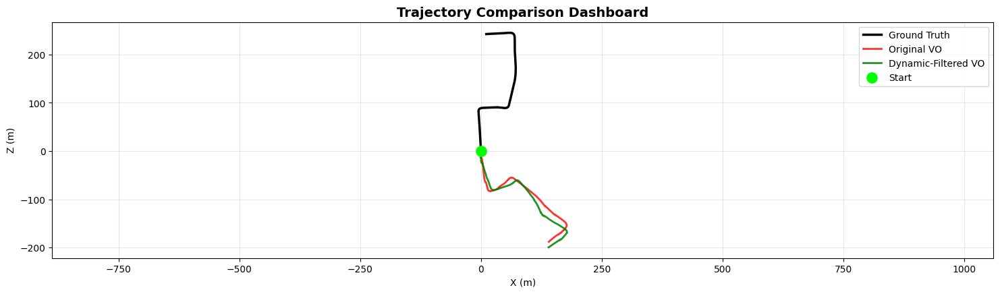

In [26]:
#Full Pipeline Function
def get_dynamic_mask(img_path, conf=0.4):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    results = yolo_model.predict(img_path, conf=conf, classes=DYNAMIC_CLASSES, verbose=False)
    if results[0].boxes is not None:
        for box in results[0].boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = map(int, box)
            cv2.rectangle(mask, (x1, y1), (x2, y2), 255, -1)
    return mask


def run_full_vo(max_frames=500, use_filtering=True):
    current_pose = np.eye(4)
    trajectory = [np.array([0., 0., 0.])]
    feature_stats = []

    for i in tqdm(range(max_frames), desc="Filtered VO" if use_filtering else "Original VO"):
        img1 = cv2.imread(left_images[i], cv2.IMREAD_GRAYSCALE)
        img2 = cv2.imread(left_images[i+1], cv2.IMREAD_GRAYSCALE)

        kps1, des1 = orb.detectAndCompute(img1, None)
        kps2, des2 = orb.detectAndCompute(img2, None)

        if des1 is None or des2 is None:
            trajectory.append(current_pose[:3, 3].copy())
            feature_stats.append(0)
            continue

        if use_filtering:
            mask1 = get_dynamic_mask(left_images[i])
            mask2 = get_dynamic_mask(left_images[i+1])
            idx1 = [j for j, kp in enumerate(kps1) if mask1[int(kp.pt[1]), int(kp.pt[0])] == 0]
            idx2 = [j for j, kp in enumerate(kps2) if mask2[int(kp.pt[1]), int(kp.pt[0])] == 0]

            if len(idx1) < 20 or len(idx2) < 20:
                trajectory.append(current_pose[:3, 3].copy())
                feature_stats.append(0)
                continue

            kps1 = [kps1[j] for j in idx1]
            des1 = des1[idx1]
            kps2 = [kps2[j] for j in idx2]
            des2 = des2[idx2]

        matches = bf.knnMatch(des1, des2, k=2)
        good = [m for m, n in matches if m.distance < 0.75 * n.distance]

        feature_stats.append(len(good))

        if len(good) < 20:
            trajectory.append(current_pose[:3, 3].copy())
            continue

        pts1 = np.float32([kps1[m.queryIdx].pt for m in good])
        pts2 = np.float32([kps2[m.trainIdx].pt for m in good])

        E, mask = cv2.findEssentialMat(pts1, pts2, K, method=cv2.RANSAC, prob=0.999, threshold=1.0)
        if E is None:
            trajectory.append(current_pose[:3, 3].copy())
            continue

        _, R, t, _ = cv2.recoverPose(E, pts1, pts2, K, mask=mask)

        scale = np.linalg.norm(gt_poses[i+1][:3, 3] - gt_poses[i][:3, 3])
        if scale < 1e-6:
            scale = 1.0
        t *= scale

        rel = np.eye(4)
        rel[:3, :3] = R
        rel[:3, 3] = t.flatten()
        current_pose = current_pose @ rel
        trajectory.append(current_pose[:3, 3].copy())

    return np.array(trajectory), feature_stats


# ----------------------------------------------------------
# 3. Run both pipelines
# ----------------------------------------------------------
print("Running Original VO...")
traj_orig, stats_orig = run_full_vo(max_frames=500, use_filtering=False)

print("\nRunning Dynamic-Filtered VO...")
traj_filt, stats_filt = run_full_vo(max_frames=500, use_filtering=True)

gt_sub = gt_xyz[:len(traj_orig)]

# ----------------------------------------------------------
# 4. Trajectory Dashboard
# ----------------------------------------------------------
fig = plt.figure(figsize=(18, 10))

# Main trajectory plot
ax1 = plt.subplot(2, 2, (1, 2))
ax1.plot(gt_sub[:, 0], gt_sub[:, 2], label="Ground Truth", linewidth=2.5, color="black")
ax1.plot(traj_orig[:, 0], traj_orig[:, 2], label="Original VO", linewidth=2, color="red", alpha=0.8)
ax1.plot(traj_filt[:, 0], traj_filt[:, 2], label="Dynamic-Filtered VO", linewidth=2, color="green", alpha=0.85)
ax1.scatter(gt_sub[0, 0], gt_sub[0, 2], c="lime", s=120, label="Start", zorder=5)
ax1.set_xlabel("X (m)")
ax1.set_ylabel("Z (m)")
ax1.set_title("Trajectory Comparison Dashboard", fontsize=14, fontweight="bold")
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.axis("equal")

### FEATURE MATCHES OVER TIME

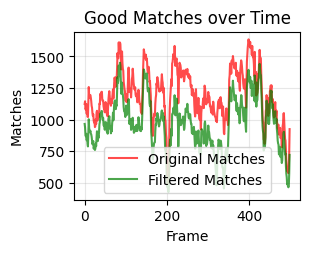

In [27]:
ax2 = plt.subplot(2, 2, 3)
ax2.plot(stats_orig, label="Original Matches", color="red", alpha=0.7)
ax2.plot(stats_filt, label="Filtered Matches", color="green", alpha=0.7)
ax2.set_title("Good Matches over Time")
ax2.set_xlabel("Frame")
ax2.set_ylabel("Matches")
ax2.legend()
ax2.grid(True, alpha=0.3)

### ERROR OVER TIME

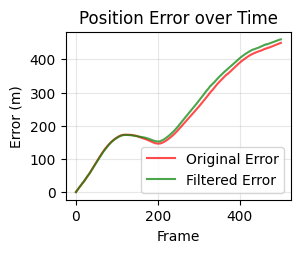

In [28]:
ax3 = plt.subplot(2, 2, 4)
err_orig = np.linalg.norm(traj_orig - gt_sub[:len(traj_orig)], axis=1)
err_filt = np.linalg.norm(traj_filt - gt_sub[:len(traj_filt)], axis=1)
ax3.plot(err_orig, label="Original Error", color="red", alpha=0.7)
ax3.plot(err_filt, label="Filtered Error", color="green", alpha=0.7)
ax3.set_title("Position Error over Time")
ax3.set_xlabel("Frame")
ax3.set_ylabel("Error (m)")
ax3.legend()
ax3.grid(True, alpha=0.3)

### FINAL METRICS

In [30]:
def compute_ate(traj, gt):
    min_len = min(len(traj), len(gt))
    return np.sqrt(np.mean(np.sum((traj[:min_len] - gt[:min_len])**2, axis=1)))

ate_orig = compute_ate(traj_orig, gt_sub)
ate_filt = compute_ate(traj_filt, gt_sub)
drift_orig = np.linalg.norm(traj_orig[-1] - gt_sub[len(traj_orig)-1])
drift_filt = np.linalg.norm(traj_filt[-1] - gt_sub[len(traj_filt)-1])

results_df = pd.DataFrame({
    "Method": ["Original VO", "Dynamic-Filtered VO"],
    "ATE (m)": [f"{ate_orig:.2f}", f"{ate_filt:.2f}"],
    "Final Drift (m)": [f"{drift_orig:.2f}", f"{drift_filt:.2f}"],
    "Avg Matches": [f"{np.mean(stats_orig):.1f}", f"{np.mean(stats_filt):.1f}"]
})

display(results_df)

,Method,ATE (m),Final Drift (m),Avg Matches
0,Original VO,270.43,449.78,1195.2
1,Dynamic-Filtered VO,279.96,460.35,971.4


---------------------------------------------

## Project Complete

##### You now have a full professional pipeline for Visual SLAM with Dynamic Object Handling:


### 1 KITTI Data Exploration

### 2 ORB Feature Detection & Matching

### 3 Classic Visual Odometry

### 4 Dynamic Object Detection (YOLO)

### 5 Dynamic Feature Filtering

### 6 Side-by-side Comparison

### 7 Full Pipeline + Dashboard